In [1]:
%matplotlib inline

import numpy as np
from numpy.random import randn

import matplotlib
import matplotlib.pyplot as plt

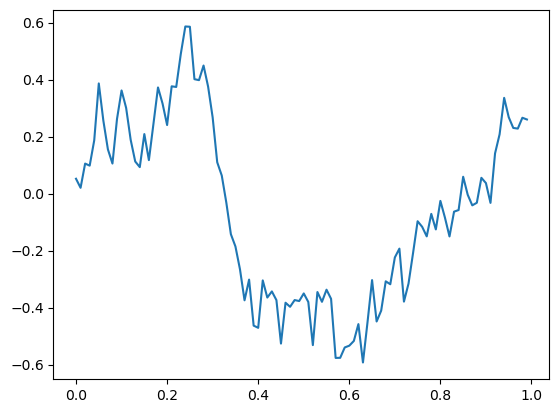

In [7]:
N=100
dt = 1.0 / N
t = np.arange(0.0,1.0, dt)
dW = np.sqrt(dt)*randn(N)
W = np.cumsum(dW)

plt.plot(t, W);

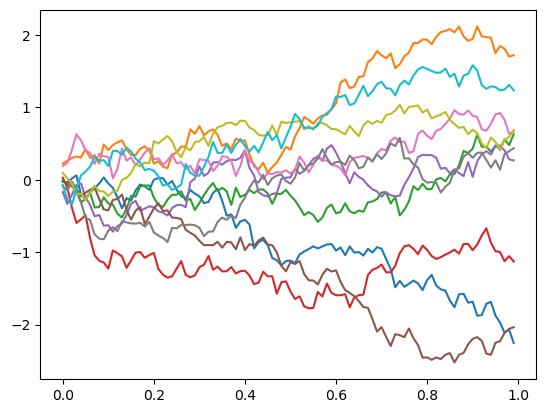

In [8]:
N=100
M=10
dt = 1.0 / N
t = np.arange(0.0,1.0, dt)
dW = np.sqrt(dt)*randn(N,M)
W = np.cumsum(dW,axis=0)

plt.plot(t, W);

Next, let's evaluate function $u(W(t)) = exp(t + \frac{1}{2}W(t))$ along 1000 discretized motion pathes.

In [10]:
import numpy.matlib

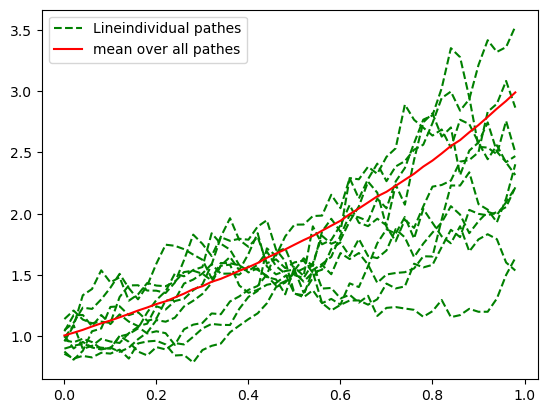

In [11]:
N=50;
M=1000;
dt = 1.0 / N;
t = np.arange(0.0,1.0, dt);
dW = np.sqrt(dt)*randn(N,M);
W = np.cumsum(dW,axis=0);
t_  = np.transpose(numpy.matlib.repmat(t, M,1));
u=np.exp(t_+ 0.5*W);
u_mean = np.mean(u, axis=1);
h1 = plt.plot(t, u[:,np.arange(10,20)],'g--', label="Lineindividual pathes")[1];
h2, = plt.plot(t, u_mean, 'r-', label="mean over all pathes");
plt.legend(handles=[h1,h2]);

For suitable function h, the integral $ \int_0^{T} h(t)dt $ may be approximated by Riemann sum: $$ \sum_{j=0}^{N-1} h(t_j) (t_{j+1}-t_j) $$ where discrete points $t_j=j\delta t$. The integral may be defined by taking limit $\delta t \to 0$. In similar way we may consider the following form: $$ \sum_{j=0}^{N-1} h(t_j) (W(t_{j+1})-W(t_j)) $$ which may be regarded as approximation to stochastic integral $ \int_0^{T} h(t)dW(t) $. Here we are integrating with respect to Brownian motion. This sum is aproximation to what is known as $It\hat{o}$ integral.

Alternatively we can implement integral as: $$\sum_{j=0}^{N-1}h\big(\frac{t_j+t_{j+1}}{2}\big)(W(t_{j+1})-W(t_j))$$

In case where $h(t) \equiv W(t)$, the sum above requires to be evaluated at $t=(t_{j+1}+t_j)/2$. It can be shown that forming $(W(t_j) + W(t_{j+1}))/2$ and adding independent $N(0, \Delta t /4 )$ increment, gives a value for $(W(t_j) + W(t_{j+1}))/2$ that maintains all three conditions of Brownian motion. This "midpoint" sums approximates $Stratonovich$ integral.

Let's evalutate precisely the integral for the case $h(t) \equiv W(t)$ that was approximated above in two ways. The $It\hat{o}$ limiting cases is $$ \sum_{j=0}^{N-1} W(t_j) (W(t_{j+1})-W(t_j)) = \frac{1}{2} \sum_{j=0}^{N-1} ({W(t_{j+1})}^2 - {W(t_{j+1})}^2 + 2 W(t_j) W(t_{j+1}) - {W(t_j)}^2 - {W(t_j)}^2) = \frac{1}{2} \sum_{j=0}^{N-1} ({W(t_{j+1})}^2 - {W(t_j)}^2 - (W(t_{j+1}) - W(t_j))^2 ) $$

$$ = \frac{1}{2} (W(T)^2 - W(0)^2) - \frac{1}{2} \sum_{j=0}^{N-1} (W(t_{j+1}) - W(t_j))^2 $$
The term $\sum_{j=0}^{N-1} (W(t_{j+1}) - W(t_j))^2$ is variance of Wiener process, which is known to be T. So the value of integrals is $\frac{1}{2}(W(T)^2 - T)$

The Stratonovich integrals is the limiting case of:

$$ \sum_{j=0}^{N-1} \Big(\frac{W(t_{j+1})-W(t_j)}{2} + \Delta Z_j \Big) (W(t_{j+1})-W(t_j)) $$
where each $Z_j$ is independent $N(0, \Delta t /4)$. This sum collapses to:

$$ \frac{1}{2} ( {W(T)}^2 - {W(0)}^2) + \sum_{j=0}^{N-1} \Delta Z_j (W(t_{j+1})-W(t_j)) $$
. The term $\sum_{j=0}^{N-1} \Delta Z_j (W(t_{j+1})-W(t_j))$ has expected value 0 and variance $\delta t$. So the integral $ \int_0^{T} W(t)dW(t) = \frac{1}{2}W(T)^2 $

So let's evaluate numerically integrals with both ways and compare with theoretical results.

In [12]:
N=10000;
M=1;
T = 1.0
dt = T / N;

t = np.arange(0.0,1.0, dt);
dW = np.sqrt(dt)*randn(N,M);
W = np.cumsum(dW,axis=0);
e = np.array([[0]])
W_=np.concatenate((e,W[:-1]), axis=0)

ito = np.dot(W_.T,dW)
print("error ito integral = ", np.abs(ito - 0.5*(W[-1]**2 - T) )[0][0])
stratonovich = np.dot((0.5*(W_ + W) + 0.25*np.sqrt(dt)*randn(N,M)).T, dW)
print("error stratonovich = ", np.abs(stratonovich - 0.5*W[-1]**2)[0][0])

error ito integral =  0.011030701014221211
error stratonovich =  0.0009394729218528131


### The Euler-Maruyama Method

An autonous scalar stochastic differential equation can be written in the integral form:

$$X(t)=X_0 + \int_0^t f(X(s))ds + \int_0^t g(X(s))dW(s), 0 \le t \le T$$
Here, $f$ and $g$ are scalar functions and initial condition X_0 is random variable. Here we take $It\hat{o}$ version of integral. The solutio $X(t)$ is a random variable for each t.

It is common to write this integral solution in differential form:

$$dX(t)=f(X(t))dt + g(X(t))dW(t), X(0)=X_0, 0 \le t \le T $$
Let's solve this equation numerically. We begin with discretising interval $[0,T]$. So let $\Delta t = T/L$ for some positive integer $L$, and $\tau_j = j \Delta t$. Also let denote $X_j = X(\tau_j)$. The Euler-Maruyama (EM) method takes the form:

$$X_j = X_{j-1} +f(X_{j-1}) \Delta t + g(X_{j-1})(W(\tau_j) - W(\tau_{j-1})), j=1,2...L $$
Which is straightforward approach similar to Euler method for ODE. So let's apply this method to the most fundamental SDE in financial mathematics - Black-Scholes linear SDE:

$$dX(t)=\lambda X(t)dt + \mu X(t)DW(t), X(0)=X_0$$
Here $\lambda$ and $\mu$ are constants. For this SDE there is the exact solution: $$X(t)=X(0)e^{(\lambda - \frac{1}{2}\mu^2)t + \mu W(t)}$$

2.528376409812463


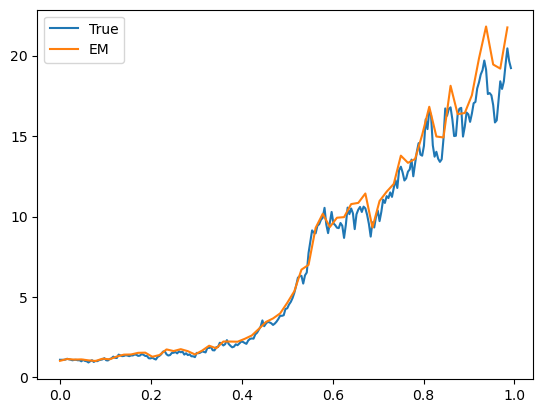

In [13]:
lambda_ = 2
mu = 1
Xzero = 1

T = 1
N = 2**8
dt = 1/N

t = np.arange(0.0,1.0, dt);
dW = np.sqrt(dt)*randn(N);
W = np.cumsum(dW);

Xtrue = Xzero*np.exp(((lambda_ - 0.5*mu**2)*t[1:])+(mu*W[:-1])) # true solution

R = 4
Dt = R*dt
L = int(N/R) # L EM steps of size Dt = R*dt
Xem = np.zeros(L)
Xtemp = Xzero;
for j in range(L):
    Winc = np.sum(dW[R*(j-1):R*j]);
    Xtemp = Xtemp + Dt*lambda_*Xtemp + mu*Xtemp*Winc;
    Xem[j] = Xtemp
    
h1, = plt.plot(t[:-1], Xtrue, label="True");
h2, = plt.plot(np.arange(0.0, 1.0, R*dt), Xem, label="EM");
plt.legend(handles=[h1,h2]);

emerr = np.abs(Xem[-1]-Xtrue[-1])
print(emerr)